In [7]:
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque
G = nx.Graph()

edges = [
    ('A','B'),('A','C'),
    ('B','D'),('B','E'),
    ('C','F'),('C','G'),
    ('E','H')
]

G.add_edges_from(edges)

BFS Traversal ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']


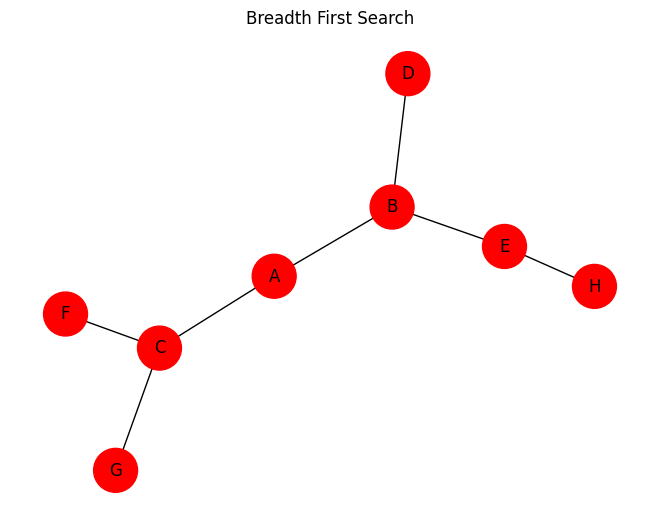

In [42]:
#BFS
start = 'A'
visited = []
queue = deque([start])

while queue:
  node = queue.popleft()
  if node not in visited:
    visited.append(node)
    queue.extend(sorted(set(G.neighbors(node)) - set(visited)))
print("BFS Traversal", visited)

pos = nx.spring_layout(G, seed=42)
node_colors = ['red' if node in visited else 'lightblue' for node in G.nodes()]
nx.draw(G, pos, with_labels=True, node_size=1000, node_color=node_colors, font_size=12)
plt.title("Breadth First Search")
plt.show()

BFS Traversal Order:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']


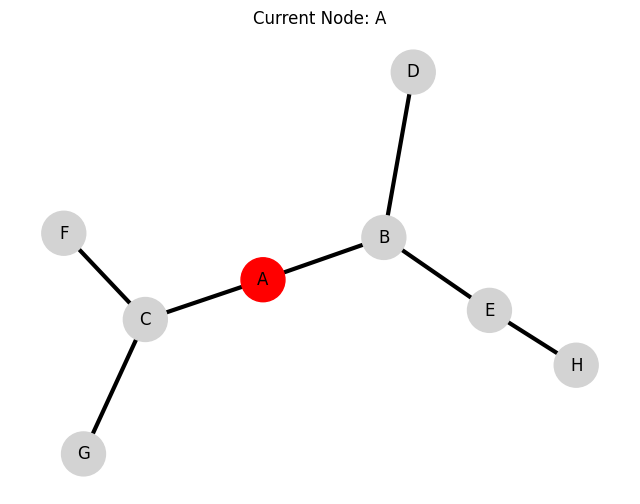

In [41]:
import networkx as nx
import matplotlib.pyplot as plt

from matplotlib.animation import FuncAnimation
from collections import deque

from IPython.display import HTML

# Create Graph
G = nx.Graph()

edges = [
    ('A','B'),
    ('A','C'),
    ('B','D'),
    ('B','E'),
    ('C','F'),
    ('C','G'),
    ('E','H')
]

G.add_edges_from(edges)

#BFS Traversal
visited = []
parent = {}
queue = deque(['A'])

while queue:
  node = queue.popleft()
  if node not in visited:
    visited.append(node)
    for neighbor in G.neighbors(node):
      if neighbor not in visited and neighbor not in queue:
        parent[neighbor] = node
        queue.append(neighbor)
print("BFS Traversal Order:")
print(visited)

#Graph Layout

pos = nx.spring_layout(G,seed=5)

fig,ax = plt.subplots(figsize=(8,6))

#Animation Function
def update(frame):
  ax.clear()
  visited_now = visited[:frame+1]
  node_colors = [
    'red' if n in visited_now else 'lightgray'
    for n in G.nodes()
]
  edge_colors = []
  for u,v in G.edges():
    if ((v in parent and parent[v]==  u and v in visited_now)
      or (u in parent and parent[u]== v and u in visited_now)):
      edge_colors.append('green')
    else:
      edge_colors.append('black')


  nx.draw(
    G,
    pos,
    ax=ax,
    with_labels=True,
    node_color=node_colors,
    edge_color=edge_colors,
    node_size=1000,
    width=3
)
  ax.set_title(
  f"Current Node: {visited[frame]}"
)

#Generate Animation
ani = FuncAnimation(
    fig,
    update,
    frames=len(visited),
    interval = 1200,
    repeat = False
)

HTML(ani.to_jshtml())

DFS Traversal Order: ['A', 'C', 'G', 'F', 'B', 'E', 'H', 'D']


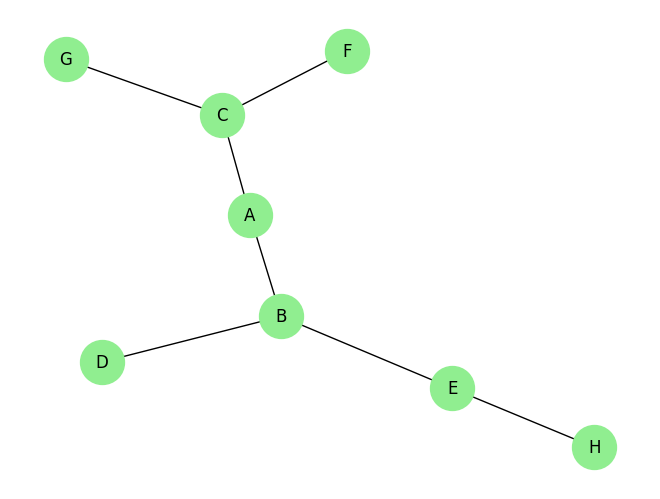

In [59]:
#DFS
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque

start = 'A'
dfs_visited = []
dfs_parent = {}
stack = [start]

while stack:
  node = stack.pop()
  if node not in dfs_visited:
    dfs_visited.append(node)
    for neighbor in G.neighbors(node):
      if neighbor not in dfs_visited:
        dfs_parent[neighbor] = node
        stack.append(neighbor)
print("DFS Traversal Order:",dfs_visited)

nx.draw(G,with_labels=True, node_size=1000, node_color="Lightgreen", font_size=12)
plt.show()